# 08 PatchTST风格的小规模追加对照

**实验顺序披露：本实验在TSMixer最终测试成绩已经查看后追加，不是完全预注册的盲测比较。**
只固定一次配置，只用2024验证MAE早停；测试结果不驱动任何重新训练。
与06相同的17站、72→24小时、封顶目标、完整联合窗口、训练/验证划分、种子42、Adam学习率0.001、最多15轮及耐心值4。

参考[PatchTST官方实现](https://github.com/yuqinie98/PatchTST/blob/main/PatchTST_supervised/layers/PatchTST_backbone.py)。
这是独立的简化实现：非重叠12小时片段、通道独立共享编码器、可学习位置嵌入、两层Transformer、维度16、4个注意力头、前馈维度32、dropout 0.1。
使用LayerNorm、标准注意力（无跨层残差注意力）、共享展平预测头、无可学习仿射的输入窗口归一化及输出反归一化。
不同于官方默认配置；不是论文复现，不能据此判断完整PatchTST架构优劣。
通道独立意味着各站共享权重但不互相注意；TSMixer会混合站点，因此比较的是整套模型设计，不是纯粹注意力消融。


In [1]:
import os
os.environ['MKL_THREADING_LAYER'] = 'SEQUENTIAL'  # 避免Anaconda与PyTorch的OpenMP冲突
import torch  # 在NumPy之前加载运行库；重跑前请重启内核
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src/aqhi_data.py').exists(): ROOT=ROOT.parent
design_files=sorted((ROOT/'data/processed/design').glob('*/design.json'))
assert design_files, '请先运行04'
design=json.loads(design_files[-1].read_text(encoding='utf-8'))
SOURCE=Path(design['source'])
STATIONS=design['comparison_targets']
assert len(STATIONS)==17 and 'Tap Mun' not in STATIONS
L,H=design['lookback'],design['horizon']
assert (L,H)==(72,24)
train_end=pd.Timestamp(design['train_end_inclusive']).tz_convert('Asia/Hong_Kong')
val_end=pd.Timestamp(design['validation_end_inclusive']).tz_convert('Asia/Hong_Kong')
h=pd.read_csv(SOURCE/'history_all_audited.csv.gz',keep_default_na=False,dtype={'source_date':str})
h=h.loc[h.source_date.ge('2020-06-01') & h.station_id.isin(STATIONS)].copy()
h['timestamp']=pd.to_datetime(h.timestamp,utc=True).dt.tz_convert('Asia/Hong_Kong')
# 在计算特征、窗口及指标之前，排除最终测试期。
h=h.loc[h.timestamp.le(val_end)].copy()
for col in ['is_10_plus','is_substituted']:
    if h[col].dtype!=bool:
        assert h[col].astype(str).isin(['True','False']).all()
        h[col]=h[col].astype(str).eq('True')
h['capped_aqhi']=pd.to_numeric(h.aqhi_value,errors='coerce')
h.loc[h.is_10_plus,'capped_aqhi']=10.0
assert h.loc[h.is_10_plus,'capped_aqhi'].eq(10).all()
assert not h.duplicated(['timestamp','station_id']).any()
index=pd.date_range(h.timestamp.min(),val_end,freq='h')
panel=h.pivot(index='timestamp',columns='station_id',values='capped_aqhi').reindex(index=index,columns=STATIONS)
cap=h.pivot(index='timestamp',columns='station_id',values='is_10_plus').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
star=h.pivot(index='timestamp',columns='station_id',values='is_substituted').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
OUT=ROOT/'data/processed/patchtst'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
print('输出目录：',OUT)
print('目标：封顶AQHI；测试集未参与指标计算。')

输出目录： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\patchtst\20261111_102259_281485
目标：封顶AQHI；测试集未参与指标计算。


In [2]:
arr=panel.to_numpy(dtype=float)
all_present=pd.Series(np.isfinite(arr).all(axis=1),index=index)
input_ok=all_present.astype(int).rolling(L).sum().shift(1).eq(L)
target_ok=all_present.astype(int).rolling(H).sum().shift(-(H-1)).eq(H)
end=index+pd.Timedelta(hours=H-1)
train_mask=(index<=train_end)&(end<=train_end)&input_ok.to_numpy()&target_ok.to_numpy()
val_mask=(index>train_end)&(end<=val_end)&input_ok.to_numpy()&target_ok.to_numpy()
origins=np.flatnonzero(val_mask)
assert len(origins)>0
gap_start=pd.Timestamp('2023-08-25 01:00',tz='Asia/Hong_Kong')
gap_end=pd.Timestamp('2023-09-01 00:00',tz='Asia/Hong_Kong')
for selected in [np.flatnonzero(train_mask),origins]:
    assert not (((index[selected]-pd.Timedelta(hours=L))<=gap_end)&(end[selected]>=gap_start)).any()
assert index[origins].min()>train_end and end[origins].max()<=val_end
target_indices=origins[:,None]+np.arange(H)[None,:]
y=arr[target_indices]
y_cap=cap.to_numpy()[target_indices]
y_star=star.to_numpy()[target_indices]
assert y.shape==(len(origins),H,len(STATIONS)) and np.isfinite(y).all()
print('训练期可用联合窗口：',int(train_mask.sum()))
print('验证期可用联合窗口：',len(origins))
print('验证目标形状（起点、未来小时、站点）：',y.shape)
pd.DataFrame({'forecast_start':index[np.flatnonzero(train_mask)]}).to_csv(OUT/'train_origins.csv',index=False)
pd.DataFrame({'forecast_start':index[origins]}).to_csv(OUT/'validation_origins.csv',index=False)

训练期可用联合窗口： 28957
验证期可用联合窗口： 8760
验证目标形状（起点、未来小时、站点）： (8760, 24, 17)


In [3]:
import random, time, copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
device=torch.device('cpu')
train_positions=np.flatnonzero(train_mask)
train_values=arr[index<=train_end]
mu=np.nanmean(train_values,axis=0).astype('float32')
sd=np.nanstd(train_values,axis=0).astype('float32')
sd=np.maximum(sd,1e-6)
scaled=((arr-mu)/sd).astype('float32')
class Windows(Dataset):
    def __init__(self,starts):self.starts=starts
    def __len__(self):return len(self.starts)
    def __getitem__(self,i):
        t=self.starts[i]
        return torch.from_numpy(scaled[t-L:t]),torch.from_numpy(scaled[t:t+H])
train_loader=DataLoader(Windows(train_positions),batch_size=256,shuffle=True,num_workers=0,
    generator=torch.Generator().manual_seed(SEED))
val_loader=DataLoader(Windows(origins),batch_size=512,shuffle=False,num_workers=0)
assert np.isfinite(mu).all() and np.isfinite(sd).all()
x0,y0=next(iter(train_loader))
assert torch.isfinite(x0).all() and torch.isfinite(y0).all()
np.savez(OUT/'scaler.npz',mean=mu,std=sd,stations=np.array(STATIONS))
print('torch:',torch.__version__,'device:',device,'train:',len(train_positions),'validation:',len(origins))

torch: 2.15.0+cpu device: cpu train: 28957 validation: 8760


## 1. PatchTST风格网络
输入窗口归一化仅使用预测起点之前72小时，不使用未来目标。评估时关闭dropout；预测不裁剪。

In [4]:
class PatchTSTSmall(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_len=12; self.stride=12
        self.patches=(L-self.patch_len)//self.stride+1
        self.embed=nn.Linear(self.patch_len,16)
        self.position=nn.Parameter(torch.empty(1,self.patches,16))
        nn.init.normal_(self.position,std=.02)
        self.dropout=nn.Dropout(.1)
        self.layers=nn.ModuleList([nn.TransformerEncoderLayer(d_model=16,nhead=4,
            dim_feedforward=32,dropout=.1,activation='gelu',batch_first=True,norm_first=False) for _ in range(2)])
        self.head=nn.Linear(self.patches*16,H)
    def forward(self,x):
        b,t,c=x.shape
        mean=x.mean(dim=1,keepdim=True).detach()
        scale=torch.sqrt(x.var(dim=1,keepdim=True,unbiased=False)+1e-5).detach()
        z=((x-mean)/scale).transpose(1,2).unfold(-1,self.patch_len,self.stride)
        z=z.reshape(b*c,self.patches,self.patch_len)
        z=self.dropout(self.embed(z)+self.position)
        for layer in self.layers:z=layer(z)
        out=self.head(z.reshape(b*c,-1)).reshape(b,c,H).transpose(1,2)
        return out*scale+mean
model=PatchTSTSmall().to(device)
assert model(x0[:2]).shape==(2,H,len(STATIONS))
parameter_count=sum(p.numel() for p in model.parameters())
print('参数数量：',parameter_count)
PATCH_DIR=OUT
# 训练之前保存固定配置，避免事后按测试结果改变方案。
precommit={'architecture':'PatchTST-style simplified','patch_length':12,'stride':12,
 'layers':2,'d_model':16,'heads':4,'feedforward':32,'dropout':.1,
 'seed':SEED,'max_epochs':15,'patience':4,'learning_rate':.001,'batch_size':256,
 'appendix_after_test_seen':True,'parameter_count':parameter_count,'test_driven_tuning':False}
(OUT/'precommitted_config.json').write_text(json.dumps(precommit,indent=2),encoding='utf-8')

参数数量： 7080


364

## 2. 仅训练/验证选择权重
相同最大轮数不是相同计算量；记录本次训练时间，单次CPU计时不可当作严格性能基准。

In [5]:
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
loss_fn=nn.MSELoss()
sd_t=torch.from_numpy(sd).to(device)
MAX_EPOCHS,PATIENCE=15,4
history_log=[]; best=float('inf'); best_state=None; wait=0; best_epoch=0
start=time.time()
for epoch in range(1,MAX_EPOCHS+1):
    model.train(); train_sum=0.; n=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); pred=model(xb); loss=loss_fn(pred,yb)
        assert torch.isfinite(loss)
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        train_sum+=loss.item()*len(xb);n+=len(xb)
    model.eval(); absolute=0.; count=0
    with torch.no_grad():
        for xb,yb in val_loader:
            err=(model(xb.to(device))-yb.to(device))*sd_t
            absolute+=err.abs().sum().item();count+=err.numel()
    val_mae=absolute/count
    history_log.append({'epoch':epoch,'train_standardized_MSE':train_sum/n,'validation_MAE':val_mae})
    pd.DataFrame(history_log).to_csv(OUT/'training_log.csv',index=False)
    print(f'Epoch {epoch:02d}: train MSE={train_sum/n:.4f}, validation MAE={val_mae:.4f}',flush=True)
    if val_mae<best-1e-5:
        best=val_mae;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());wait=0
    else:wait+=1
    if wait>=PATIENCE:break
assert best_state is not None
model.load_state_dict(best_state); model.eval()
torch.save(best_state,OUT/'best_model_state.pt')
training_log=pd.DataFrame(history_log)
training_log.to_csv(OUT/'training_log.csv',index=False)
print('最佳轮次：',best_epoch,'训练耗时（秒）：',round(time.time()-start,1))
training_seconds=time.time()-start

Epoch 01: train MSE=0.4726, validation MAE=0.5715


Epoch 02: train MSE=0.3966, validation MAE=0.5556


Epoch 03: train MSE=0.3860, validation MAE=0.5514


Epoch 04: train MSE=0.3814, validation MAE=0.5498


Epoch 05: train MSE=0.3787, validation MAE=0.5501


Epoch 06: train MSE=0.3776, validation MAE=0.5478


... (6 outputs left out)

Epoch 13: train MSE=0.3715, validation MAE=0.5460


Epoch 14: train MSE=0.3707, validation MAE=0.5467


Epoch 15: train MSE=0.3711, validation MAE=0.5459


最佳轮次： 15 训练耗时（秒）： 269.9


## 3. 验证集比较
复核两个基准与05一致，再读取锁定TSMixer实验结果进行横向展示。

In [6]:
with torch.no_grad():
    model_pred=np.concatenate([model(xb.to(device)).cpu().numpy() for xb,_ in val_loader],axis=0)*sd+mu
assert model_pred.shape==y.shape and np.isfinite(model_pred).all()
predictions={'Persistence':np.repeat(arr[origins-1,None,:],H,axis=1),
 'Previous day':arr[target_indices-24],'PatchTST-style':model_pred}
assert ((target_indices-24)<origins[:,None]).all()
def metric(truth,pred):
    err=pred-truth
    return {'n_forecasts':int(err.size),'MAE':float(np.abs(err).mean()) if err.size else None,
      'RMSE':float(np.sqrt(np.square(err).mean())) if err.size else None,
      'bias':float(err.mean()) if err.size else None}
results=pd.DataFrame([{'model':k,**metric(y,v)} for k,v in predictions.items()])
detail=[]; station_rows=[]; horizon_rows=[]
unique_indices=np.unique(target_indices)
for name,p in predictions.items():
    for label,mask,unique_count in [
      ('target_at_least_7',y>=7,int((arr[unique_indices]>=7).sum())),
      ('original_10_plus',y_cap,int(cap.to_numpy()[unique_indices].sum()))]:
        detail.append({'model':name,'subset':label,'unique_station_hours':unique_count,**metric(y[mask],p[mask])})
    for j,s in enumerate(STATIONS):station_rows.append({'model':name,'station_id':s,**metric(y[:,:,j],p[:,:,j])})
    for j in range(H):horizon_rows.append({'model':name,'horizon':j+1,**metric(y[:,j,:],p[:,j,:])})
display(results.round(4));display(pd.DataFrame(detail).round(4))
outside=float(((model_pred<1)|(model_pred>10)).mean())
print('未裁剪预测超出1–10的比例：',outside)
# 独立核对05保存的基准，确保相同数据与窗口。
baseline_files=sorted((ROOT/'data/processed/baselines').glob('*/overall_validation.csv'))
reference=pd.read_csv(baseline_files[-1]).set_index('model')
for name in ['Persistence','Previous day']:
    assert np.isclose(results.set_index('model').loc[name,'MAE'],reference.loc[name,'MAE'],atol=1e-9)
    assert results.set_index('model').loc[name,'n_forecasts']==reference.loc[name,'n_forecasts']
print('与05基准指标一致；最终测试集未评分。')
mixer_dir=ROOT/'data/processed/tsmixer/20261111_010719_491327'
mixer_val=pd.read_csv(mixer_dir/'comparison_validation.csv')
assert mixer_val.n_forecasts.eq(y.size).all()
assert pd.read_csv(mixer_dir/'validation_origins.csv').equals(pd.read_csv(OUT/'validation_origins.csv'))
comparison_val=pd.concat([results,mixer_val.loc[mixer_val.model.eq('TSMixer')]],ignore_index=True)
display(comparison_val.round(4))
comparison_val.to_csv(OUT/'comparison_validation.csv',index=False)
pd.DataFrame(detail).to_csv(OUT/'subset_validation.csv',index=False)
pd.DataFrame(horizon_rows).to_csv(OUT/'horizon_validation.csv',index=False)
pd.DataFrame(station_rows).to_csv(OUT/'station_validation.csv',index=False)
config={**precommit,'source':str(SOURCE),'stations':STATIONS,'lookback':L,'horizon':H,
 'train_end':str(train_end),'validation_end':str(val_end),'target':'capped AQHI; 10+ encoded as 10',
 'best_epoch':best_epoch,'training_seconds':training_seconds,'torch_version':str(torch.__version__),
 'test_evaluated_during_training':False,'output_clipping':False}
(OUT/'model_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')


,model,n_forecasts,MAE,RMSE,bias
0,Persistence,3574080,0.6630,1.0501,0.0002
1,Previous day,3574080,0.6163,0.9638,-0.0013
2,PatchTST-style,3574080,0.5459,0.7691,-0.0624


,model,subset,unique_station_hours,n_forecasts,MAE,RMSE,bias
0,Persistence,target_at_least_7,1860,43682,2.7508,3.2048,-2.6531
1,Persistence,original_10_plus,14,336,5.4048,5.7972,-5.4048
2,Previous day,target_at_least_7,1860,43682,2.2932,2.6283,-2.1812
3,Previous day,original_10_plus,14,336,4.5714,4.6445,-4.5714
4,PatchTST-style,target_at_least_7,1860,43682,2.2966,2.6453,-2.2809
5,PatchTST-style,original_10_plus,14,336,4.8614,5.0662,-4.8614


未裁剪预测超出1–10的比例： 0.0003821962574984332
与05基准指标一致；最终测试集未评分。


,model,n_forecasts,MAE,RMSE,bias
0,Persistence,3574080,0.6630,1.0501,0.0002
1,Previous day,3574080,0.6163,0.9638,-0.0013
2,PatchTST-style,3574080,0.5459,0.7691,-0.0624
3,TSMixer,3574080,0.5311,0.7322,-0.0394


1130

## 4. 权重锁定后的追加测试
下面只加载选好的权重。测试已被此前实验查看过，因此报告应称为追加对照，不应称为全新盲测。

In [7]:
import os
os.environ['MKL_THREADING_LAYER']='SEQUENTIAL'
import torch
from torch import nn
from pathlib import Path
from datetime import datetime
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src/aqhi_data.py').exists(): ROOT=ROOT.parent
MODEL_DIR=PATCH_DIR
config=json.loads((MODEL_DIR/'model_config.json').read_text(encoding='utf-8'))
SOURCE=Path(config['source'])
STATIONS=config['stations']; L=config['lookback']; H=config['horizon']
assert len(STATIONS)==17 and (L,H)==(72,24)
assert config['patch_length']==12 and config['d_model']==16
torch.set_num_threads(4); torch.manual_seed(config['seed'])
torch.use_deterministic_algorithms(True)
scaler=np.load(MODEL_DIR/'scaler.npz')
assert scaler['stations'].tolist()==STATIONS
mu,sd=scaler['mean'],scaler['std']
test_boundary=pd.Timestamp(config['validation_end']).tz_convert('Asia/Hong_Kong')
test_end=pd.Timestamp('2026-07-01 00:00',tz='Asia/Hong_Kong')
OUT=PATCH_DIR/'posthoc_test'
OUT.mkdir(parents=True,exist_ok=False)
lock={'model_directory':str(MODEL_DIR),'model_sha256':hashlib.sha256((MODEL_DIR/'best_model_state.pt').read_bytes()).hexdigest(),
 'scaler_sha256':hashlib.sha256((MODEL_DIR/'scaler.npz').read_bytes()).hexdigest(),
 'test_start_exclusive':str(test_boundary),'test_end_inclusive':str(test_end),
 'retraining':False,'clipping':False,'selection':'fixed before evaluating test',
 'lookback':L,'horizon':H,'stations':STATIONS,'target':config['target']}
(OUT/'evaluation_lock.json').write_text(json.dumps(lock,ensure_ascii=False,indent=2),encoding='utf-8')
print('锁定模型：',MODEL_DIR)
print('输出目录：',OUT)

锁定模型： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\patchtst\20261111_102259_281485
输出目录： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\patchtst\20261111_102259_281485\posthoc_test


In [8]:
h=pd.read_csv(SOURCE/'history_all_audited.csv.gz',keep_default_na=False,dtype={'source_date':str})
h=h.loc[h.station_id.isin(STATIONS)].copy()
h['timestamp']=pd.to_datetime(h.timestamp,utc=True).dt.tz_convert('Asia/Hong_Kong')
h=h.loc[h.timestamp.ge(test_boundary-pd.Timedelta(hours=L-1))&h.timestamp.le(test_end)].copy()
for col in ['is_10_plus','is_substituted']:
    if h[col].dtype!=bool:
        assert h[col].astype(str).isin(['True','False']).all()
        h[col]=h[col].astype(str).eq('True')
h['capped_aqhi']=pd.to_numeric(h.aqhi_value,errors='coerce')
h.loc[h.is_10_plus,'capped_aqhi']=10.0
assert not h.duplicated(['timestamp','station_id']).any()
index=pd.date_range(test_boundary-pd.Timedelta(hours=L-1),test_end,freq='h')
panel=h.pivot(index='timestamp',columns='station_id',values='capped_aqhi').reindex(index=index,columns=STATIONS)
cap=h.pivot(index='timestamp',columns='station_id',values='is_10_plus').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
arr=panel.to_numpy(dtype=float)
present=pd.Series(np.isfinite(arr).all(axis=1),index=index)
valid=present.astype(int).rolling(L).sum().shift(1).eq(L)&present.astype(int).rolling(H).sum().shift(-(H-1)).eq(H)
in_test=(index>test_boundary)&((index+pd.Timedelta(hours=H-1))<=test_end)
origins=np.flatnonzero(valid.to_numpy()&in_test)
assert len(origins)>0 and origins.min()>=L
ti=origins[:,None]+np.arange(H)
assert index[ti.min()]>test_boundary and index[ti.max()]<=test_end
y=arr[ti]; ycap=cap.to_numpy()[ti]
assert np.isfinite(y).all()
coverage={'candidate_origins':int(in_test.sum()),'usable_origins':len(origins),
 'usable_origin_fraction':float(len(origins)/in_test.sum()),'unique_target_station_hours':int(len(np.unique(ti))*len(STATIONS))}
print(coverage)
pd.DataFrame({'forecast_start':index[origins]}).to_csv(OUT/'test_origins.csv',index=False)
(OUT/'coverage.json').write_text(json.dumps(coverage,indent=2),encoding='utf-8')

{'candidate_origins': 13081, 'usable_origins': 12450, 'usable_origin_fraction': 0.9517620976989527, 'unique_target_station_hours': 213996}


148

In [9]:
model=PatchTSTSmall()
model.load_state_dict(torch.load(MODEL_DIR/'best_model_state.pt',map_location='cpu',weights_only=True),strict=True)
model.eval()
scaled=((arr-mu)/sd).astype('float32')
chunks=[]
with torch.inference_mode():
    for start in range(0,len(origins),512):
        positions=origins[start:start+512]
        batch=np.stack([scaled[t-L:t] for t in positions])
        assert np.isfinite(batch).all()
        chunks.append(model(torch.from_numpy(batch)).numpy())
prediction=np.concatenate(chunks)*sd+mu
assert prediction.shape==y.shape and np.isfinite(prediction).all()
assert (ti-24<origins[:,None]).all()
predictions={'Persistence':np.repeat(arr[origins-1,None,:],H,axis=1),
 'Previous day':arr[ti-24],'PatchTST-style':prediction}
assert hashlib.sha256((MODEL_DIR/'best_model_state.pt').read_bytes()).hexdigest()==lock['model_sha256']
print('推理完成；权重校验未改变。')

推理完成；权重校验未改变。


In [10]:
def metric(a,b):
    e=b-a
    return {'n_forecasts':int(e.size),'MAE':float(np.abs(e).mean()) if e.size else None,
      'RMSE':float(np.sqrt(np.square(e).mean())) if e.size else None,'bias':float(e.mean()) if e.size else None}
overall=[]; subsets=[]; station=[]; horizon=[]; monthly=[]
unique=np.unique(ti)
for name,p in predictions.items():
    overall.append({'model':name,**metric(y,p)})
    for label,mask,count in [('target_at_least_7',y>=7,int((arr[unique]>=7).sum())),
       ('original_10_plus',ycap,int(cap.to_numpy()[unique].sum()))]:
        subsets.append({'model':name,'subset':label,'unique_station_hours':count,**metric(y[mask],p[mask])})
    for j,s in enumerate(STATIONS):station.append({'model':name,'station_id':s,**metric(y[:,:,j],p[:,:,j])})
    for j in range(H):horizon.append({'model':name,'horizon':j+1,**metric(y[:,j,:],p[:,j,:])})
    for month in sorted(set(index[origins].strftime('%Y-%m'))):
        mask=index[origins].strftime('%Y-%m')==month
        monthly.append({'model':name,'forecast_start_month':month,**metric(y[mask],p[mask])})
overall=pd.DataFrame(overall); subsets=pd.DataFrame(subsets)
display(overall.round(4));display(subsets.round(4))
baseline=overall.set_index('model').loc['Previous day']
mixer=overall.set_index('model').loc['PatchTST-style']
print('相对前一天基准MAE改善百分比（负值表示变差）：',100*(1-mixer.MAE/baseline.MAE))
print('预测超出1–10范围的比例：',float(((prediction<1)|(prediction>10)).mean()))
locked_test=ROOT/'data/processed/final_test/20261111_011923_374913'
assert pd.read_csv(locked_test/'test_origins.csv').equals(pd.read_csv(OUT/'test_origins.csv'))
old=pd.read_csv(locked_test/'overall_test.csv')
assert old.n_forecasts.eq(y.size).all()
combined_test=pd.concat([overall,old.loc[old.model.eq('TSMixer')]],ignore_index=True)
display(combined_test.round(4))
combined_test.to_csv(OUT/'comparison_all_models_test.csv',index=False)


,model,n_forecasts,MAE,RMSE,bias
0,Persistence,5079600,0.6225,0.9971,0.0027
1,Previous day,5079600,0.6219,0.9702,0.0060
2,PatchTST-style,5079600,0.5514,0.7828,-0.0529


,model,subset,unique_station_hours,n_forecasts,MAE,RMSE,bias
0,Persistence,target_at_least_7,2976,71003,2.4295,2.9782,-2.1740
1,Persistence,original_10_plus,55,1320,2.8591,3.3925,-2.8591
2,Previous day,target_at_least_7,2976,71003,2.3969,2.9339,-2.0710
3,Previous day,original_10_plus,55,1320,2.5636,2.8572,-2.5636
4,PatchTST-style,target_at_least_7,2976,71003,2.3180,2.7637,-2.2651
5,PatchTST-style,original_10_plus,55,1320,3.7495,4.0119,-3.7491


相对前一天基准MAE改善百分比（负值表示变差）： 11.333854855723569
预测超出1–10范围的比例： 0.00019706276084731082


,model,n_forecasts,MAE,RMSE,bias
0,Persistence,5079600,0.6225,0.9971,0.0027
1,Previous day,5079600,0.6219,0.9702,0.0060
2,PatchTST-style,5079600,0.5514,0.7828,-0.0529
3,TSMixer,5079600,0.5383,0.7509,-0.0671


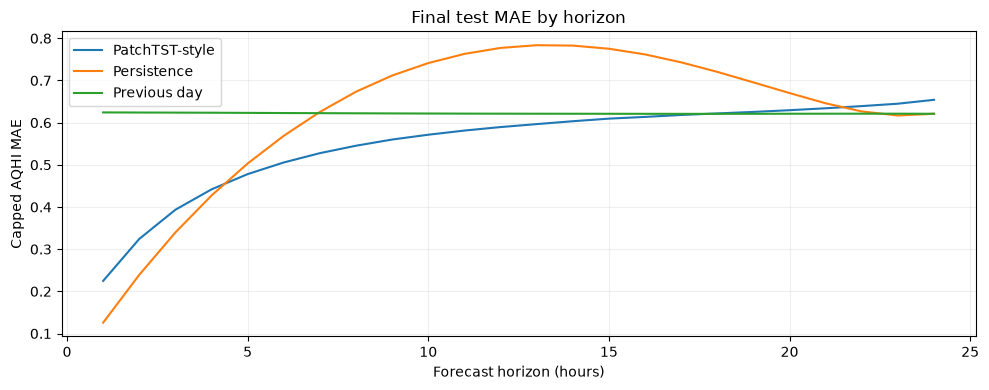

最终测试结果已保存： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\patchtst\20261111_102259_281485\posthoc_test
本次未训练、未调参、未修改模型或标准化参数。
本次对照训练耗时（秒）： 269.9
模型参数数量： 7080
这是测试已查看后的追加比较；不再按成绩搜索新参数。


In [11]:
hz=pd.DataFrame(horizon)
fig,ax=plt.subplots(figsize=(10,4))
for name,g in hz.groupby('model'):ax.plot(g.horizon,g.MAE,label=name)
ax.set(title='Final test MAE by horizon',xlabel='Forecast horizon (hours)',ylabel='Capped AQHI MAE')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(OUT/'test_mae_by_horizon.png',dpi=150);plt.show()
for name,table in {'overall_test':overall,'subset_test':subsets,'station_test':pd.DataFrame(station),
 'horizon_test':hz,'monthly_test':pd.DataFrame(monthly)}.items():
    table.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
print('最终测试结果已保存：',OUT)
print('本次未训练、未调参、未修改模型或标准化参数。')
print('本次对照训练耗时（秒）：',round(training_seconds,1))
print('模型参数数量：',parameter_count)
print('这是测试已查看后的追加比较；不再按成绩搜索新参数。')